# S9 · Game-based Behavioral Social Rank

Instead of asking children who is popular, we can read rank off the
game: PageRank on the network of tokens sent. Code:
`code/si/S9_behavioral_rank.R`.

For the regression tables, † denotes p \< 0.10, \* p \< 0.05, \*\* p \<
0.01, and \*\*\* p \< 0.001.

In [ ]:
here::i_am("notebooks/si/S9_behavioral_rank.qmd")
source(here::here("code", "00_helpers.R"))
source(here("code", "00_style.R"))
source(here("code", "si", "figures", "S9_figures.R"))   # plotting functions of this section
library(igraph)
library(patchwork)
dir.create(here("output", "figures", "si"), recursive = TRUE, showWarnings = FALSE)

dyads    <- read_csv(here("data", "generated", "analysis_dyads.csv"),    show_col_types = FALSE)
students <- read_csv(here("data", "generated", "analysis_students.csv"), show_col_types = FALSE)

save_si_figure <- function(plot, name, width, height) {
  ggsave(here("output", "figures", "si", paste0(name, ".pdf")), plot, width = width, height = height)
  ggsave(here("output", "figures", "si", paste0(name, ".png")), plot, width = width, height = height, dpi = 300)
}

In [ ]:
# PageRank of each classroom's token network: edge i -> j weighted by the
# tokens i sent to j. A child ranks high when she receives many tokens,
# especially from classmates who themselves receive many.
behavioral_rank <- dyads %>%
  transmute(class_id, from = as.character(sender_id), to = as.character(receiver_id), weight = tokens_sent) %>%
  group_by(class_id) %>%
  group_modify(function(edges, key) {
    network <- graph_from_data_frame(edges %>% filter(weight > 0),
                                     vertices = data.frame(name = unique(c(edges$from, edges$to))))
    pr <- page_rank(network, damping = 0.85)$vector
    tibble(student_id = as.numeric(names(pr)), bsr_pagerank = pr)
  }) %>%
  mutate(bsr = (bsr_pagerank - min(bsr_pagerank)) / (max(bsr_pagerank) - min(bsr_pagerank))) %>%
  ungroup()

students <- students %>% left_join(behavioral_rank %>% select(student_id, bsr_pagerank, bsr), by = "student_id")

bsr_of <- setNames(students$bsr, students$student_id)
dyads <- dyads %>%
  mutate(bsr_gap = bsr_of[as.character(sender_id)] - bsr_of[as.character(receiver_id)])

## How close is it to the nomination-based rank?

In [ ]:
# How close are the behavioral and the nomination-based ranks?
# Raw PageRank scores pooled over classrooms, the 0-1 ranks rescaled within
# classrooms, and the median within-class correlation. Raw PageRank is about
# 1 / class size, so the pooled raw correlation also reflects class size; the
# rescaled ranks compare children only within their own classroom.
tibble(
  comparison = c("Raw PageRank, pooled", "Rescaled 0-1 ranks, pooled", "Rescaled ranks, median within class"),
  pearson  = c(cor(students$bsr_pagerank, students$pagerank),
               cor(students$bsr, students$social_rank),
               students %>% group_by(class_id) %>% summarise(r = cor(bsr, social_rank)) %>% pull(r) %>% median()),
  spearman = c(cor(students$bsr_pagerank, students$pagerank, method = "spearman"),
               cor(students$bsr, students$social_rank, method = "spearman"),
               students %>% group_by(class_id) %>% summarise(r = cor(bsr, social_rank, method = "spearman")) %>%
                 pull(r) %>% median())
)

comparison,pearson,spearman
"Raw PageRank, pooled",0.8375308,0.8522072
"Rescaled 0-1 ranks, pooled",0.4451852,0.4311976
"Rescaled ranks, median within class",0.5003510,0.5093583


## Tables S53–S54. Cooperation GAP on the behavioral rank gap

Each table estimates how the Cooperation GAP changes with the sender’s
Behavioral Social Rank minus the receiver’s. Column (1) has no fixed
effects, column (2) adds classroom fixed effects, and column (3) adds
sender fixed effects. Standard errors are in parentheses.

In [ ]:
# Tables S53-S54: three specifications (no FE; classroom FE; classroom +
# sender FE) for all dyads, mutual friends and non-friends
bsr_models <- function(data, outcome) {
  data <- data %>% filter(!is.na(.data[[outcome]])) %>%
    mutate(across(c(sender_id, class_id), as.factor))
  f <- function(fe, cl) as.formula(paste(outcome, "~ bsr_gap |", fe, "| 0 |", cl))
  list("(1)" = felm(f("0", "0"), data = data),
       "(2)" = felm(f("class_id", "class_id"), data = data),
       "(3)" = felm(f("class_id + sender_id", "class_id"), data = data))
}

samples <- list("All dyads" = dyads,
                "Mutual friends" = filter(dyads, friendship == "Mutual"),
                "Non-friends" = filter(dyads, friendship == "Non-friends"))

table_s53 <- map(samples, ~ regression_table(bsr_models(.x, "coop_gap"), terms = "bsr_gap"))
table_s54 <- map(samples, ~ regression_table(bsr_models(.x, "coop_gap_filtered"), terms = "bsr_gap"))

### Table S53. Observed tokens

These models use the Cooperation GAP calculated from all observed
transfers in each sample.

#### All dyads

In [ ]:
knitr::kable(table_s53[["All dyads"]])

row,(1),(2),(3)
bsr_gap,2.888***,2.888***,2.884***
,(0.092),(0.309),(0.310)
Observations,"17,804","17,804","17,804"
R2,0.052,0.052,0.278
Adj. R2,0.052,0.050,0.241


#### Mutual friends

In [ ]:
knitr::kable(table_s53[["Mutual friends"]])

row,(1),(2),(3)
bsr_gap,1.668***,1.668*,2.062*
,(0.367),(0.638),(0.868)
Observations,"1,288","1,288","1,288"
R2,0.016,0.016,0.649
Adj. R2,0.015,-0.020,0.286


#### Non-friends

In [ ]:
knitr::kable(table_s53[["Non-friends"]])

row,(1),(2),(3)
bsr_gap,2.909***,2.909***,2.795***
,(0.104),(0.311),(0.333)
Observations,"13,916","13,916","13,916"
R2,0.053,0.053,0.292
Adj. R2,0.053,0.050,0.245


### Table S54. Filtered tokens

These models use the Cooperation GAP for pairs in which both transfers
survive the null-model filter.

#### All dyads

In [ ]:
knitr::kable(table_s54[["All dyads"]])

row,(1),(2),(3)
bsr_gap,4.044***,4.044***,4.114***
,(0.177),(0.449),(0.445)
Observations,"4,590","4,590","4,590"
R2,0.103,0.103,0.310
Adj. R2,0.102,0.094,0.160


#### Mutual friends

In [ ]:
knitr::kable(table_s54[["Mutual friends"]])

row,(1),(2),(3)
bsr_gap,0.408,0.408,-0.277
,(0.514),(0.507),(1.446)
Observations,548,548,548
R2,0.001,0.001,0.755
Adj. R2,-0.001,-0.088,0.174


#### Non-friends

In [ ]:
knitr::kable(table_s54[["Non-friends"]])

row,(1),(2),(3)
bsr_gap,4.431***,4.431***,4.505***
,(0.211),(0.467),(0.494)
Observations,"3,302","3,302","3,302"
R2,0.118,0.118,0.356
Adj. R2,0.118,0.106,0.162


## Table S55. Asymmetric friendships

These models use filtered tokens for one-sided friendship nominations.
Direction is defined by the nominator’s Behavioral Social Rank relative
to the recipient’s. The higher-to-lower group includes equal ranks,
following the rule used in the code.

In [ ]:
# Table S55: one-sided friendships (filtered tokens), split by who has the
# higher behavioral rank
asymmetric <- dyads %>%
  filter(friendship == "Sender declares", !is.na(coop_gap_filtered)) %>%
  mutate(direction = if_else(bsr_gap < 0, "Lower-to-higher", "Higher-to-lower"))

table_s55 <- asymmetric %>%
  split(.$direction) %>%
  map(~ regression_table(bsr_models(.x, "coop_gap_filtered"), terms = "bsr_gap"))

### Lower to higher Behavioral Social Rank

In [ ]:
knitr::kable(table_s55[["Lower-to-higher"]])

row,(1),(2),(3)
bsr_gap,3.996***,5.811***,0.805
,(1.093),(1.251),(2.445)
Observations,258,258,258
R2,0.050,0.215,0.854
Adj. R2,0.046,0.058,0.351


### Higher to lower Behavioral Social Rank

In [ ]:
knitr::kable(table_s55[["Higher-to-lower"]])

row,(1),(2),(3)
bsr_gap,0.983,3.371*,7.321†
,(1.828),(1.650),(3.334)
Observations,112,112,112
R2,0.003,0.489,0.962
Adj. R2,-0.006,0.223,0.582


## Figure S29

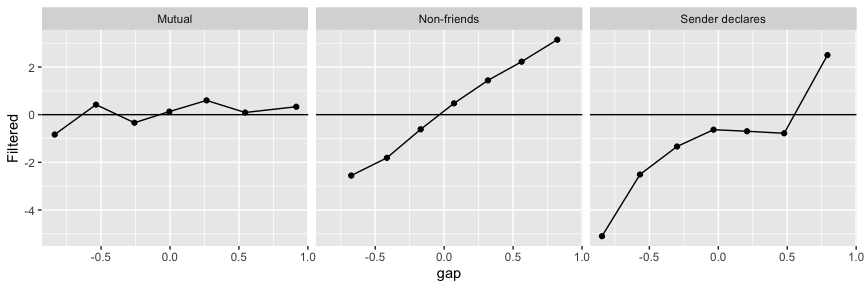

In [ ]:
# Figure 3 panels B and C with the behavioral rank gap: per-child averages,
# 7 equal-width bins (as in 05_figure3_cooperation.R), 95% CIs across children
mean_ci <- function(x) c(mean = mean(x, na.rm = TRUE),
                         ci = 1.96 * sd(x, na.rm = TRUE) / sqrt(sum(!is.na(x))))

bsr_bins <- dyads %>%
  filter(friendship %in% c("Non-friends", "Mutual", "Sender declares")) %>%
  group_by(friendship, sender_id) %>%
  summarise(gap = median(bsr_gap),
            sent = mean(tokens_sent_filtered, na.rm = TRUE),
            received = mean(tokens_received_filtered, na.rm = TRUE),
            coop_observed = mean(coop_gap),
            coop_filtered = mean(coop_gap_filtered, na.rm = TRUE), .groups = "drop") %>%
  group_by(friendship) %>% mutate(bin = cut_interval(gap, 7)) %>%
  group_by(friendship, bin) %>%
  # (the CIs are computed first: summarise() replaces each column as it goes)
  summarise(gap = mean(gap),
            sent_ci     = mean_ci(sent)[["ci"]],          sent     = mean_ci(sent)[["mean"]],
            received_ci = mean_ci(received)[["ci"]],      received = mean_ci(received)[["mean"]],
            Observed_ci = mean_ci(coop_observed)[["ci"]], Observed = mean_ci(coop_observed)[["mean"]],
            Filtered_ci = mean_ci(coop_filtered)[["ci"]], Filtered = mean_ci(coop_filtered)[["mean"]],
            .groups = "drop")

# Quick look: filtered Cooperation GAP along the behavioral rank gap
ggplot(bsr_bins, aes(gap, Filtered)) +
  geom_hline(yintercept = 0) +
  geom_line() +
  geom_point() +
  facet_wrap(~ friendship)

#### Supporting Information layout

Plotting code from `code/si/figures/S9_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S29: Figure 3 panels B and C with the Behavioral Social Rank GAP,
# one column per friendship type.
plot_figure_s29 <- function(bsr_bins, dyads) {
  s29_groups <- tribble(
    ~friendship,       ~title,        ~color,
    "Non-friends",     "Non Friends", color_non_friends,
    "Mutual",          "Mutual",      color_mutual,
    "Sender declares", "Ego declares", color_asymmetric
  )

  rank_side_labels <- annotate("text", x = c(-0.55, 0.55), y = -Inf, vjust = -0.6, size = 2,
                               fontface = "bold", label = c("Receiver has higher rank", "Sender has higher rank"))

  s29_column <- function(friendship, title, color) {
    bins <- bsr_bins %>% filter(friendship == !!friendship)
    header <- header_bar(title, color)

    tokens <- ggplot(bins, aes(gap)) +
      geom_vline(xintercept = 0, linetype = "dotted", color = "grey40") +
      geom_hline(yintercept = mean(dyads$tokens_sent), linetype = "dotted", color = "grey40") +
      geom_ribbon(aes(ymin = received, ymax = sent), fill = "#F0E5A8", alpha = 0.7) +
      geom_line(aes(y = sent), color = color, linewidth = 0.8) +
      geom_errorbar(aes(ymin = sent - sent_ci, ymax = sent + sent_ci), color = color, width = 0.03) +
      geom_point(aes(y = sent), color = color, shape = 18, size = 2.6) +
      geom_line(aes(y = received), color = color, linewidth = 0.8) +
      geom_errorbar(aes(ymin = received - received_ci, ymax = received + received_ci), color = color, width = 0.03) +
      geom_point(aes(y = received), color = color, shape = 15, size = 2) +
      rank_side_labels +
      scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
      coord_cartesian(ylim = c(-0.5, 11.5)) +
      labs(x = NULL, y = if (friendship == "Non-friends") "Tokens" else NULL) +
      theme_si(7)

    gaps <- bins %>%
      pivot_longer(c(Observed, Filtered), names_to = "version", values_to = "coop_gap") %>%
      mutate(ci = if_else(version == "Observed", Observed_ci, Filtered_ci)) %>%
      ggplot(aes(gap, coop_gap, alpha = version)) +
      geom_vline(xintercept = 0, linetype = "dotted", color = "grey40") +
      geom_hline(yintercept = 0, linetype = "dotted", color = "grey40") +
      geom_line(color = color, linewidth = 0.9) +
      geom_errorbar(aes(ymin = coop_gap - ci, ymax = coop_gap + ci), color = color, width = 0.03) +
      geom_point(color = color, size = 2) +
      annotate("text", x = 1.05, y = -4.6, hjust = 1, size = 2, fontface = "bold", color = color,
               label = "Non random") +
      annotate("text", x = 1.05, y = -5.4, hjust = 1, size = 2, fontface = "bold", color = color,
               alpha = 0.4, label = "Observed") +
      rank_side_labels +
      scale_alpha_manual(values = c(Filtered = 1, Observed = 0.4)) +
      scale_x_continuous(limits = c(-1.1, 1.1), breaks = seq(-1, 1, 0.5)) +
      coord_cartesian(ylim = c(-6.5, 6)) +
      labs(x = NULL, y = if (friendship == "Non-friends") "GAP [Received - Sent]" else NULL) +
      theme_si(7)

    header / tokens / header / gaps + plot_layout(heights = c(0.12, 1, 0.12, 1))
  }

  figure_s29 <- pmap(s29_groups, s29_column) %>%
    wrap_plots(nrow = 1) +
    plot_annotation(caption = "Behavioral Social Ranking GAP [game PageRank sender - receiver]",
                    theme = theme(plot.caption = element_text(hjust = 0.5, size = 9)))
  figure_s29
}

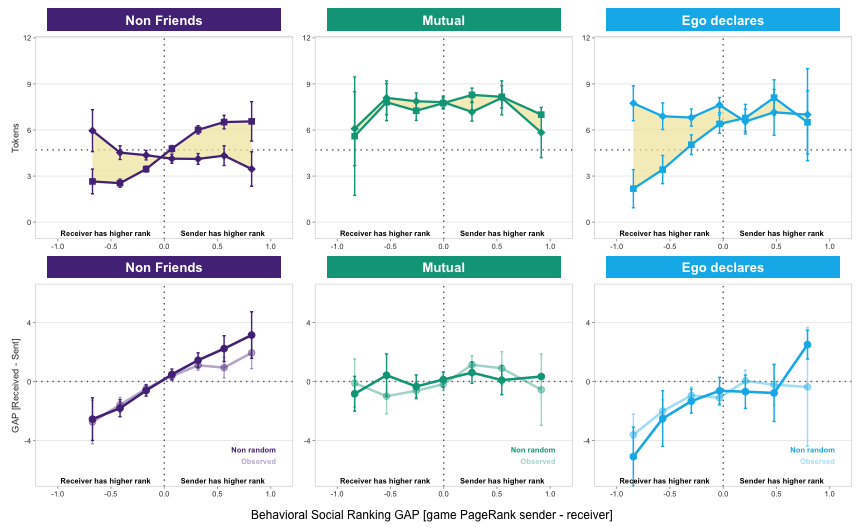

In [ ]:
# Supporting Information layout (plotting code in figures/S9_figures.R)
figure_s29 <- plot_figure_s29(bsr_bins, dyads)
figure_s29

## Figure S30

panel,r
B. Friendship nominations,0.4866695
C. Attendance previous term,0.1277592
D. Overall GPA previous term,0.3744739
E. Liked,0.5149528
F. Disliked,-0.4049296
G. Aggression,-0.1585922
H. Popularity,0.3998075


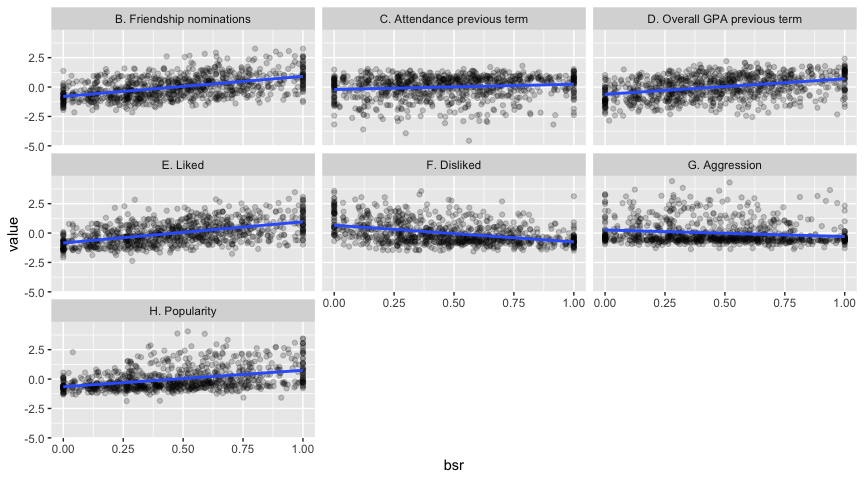

In [ ]:
# Figure S30: (A) the two PageRank scores, log scales; (B-H) Behavioral Social
# Rank against other characteristics (within-class z-scores), with binned
# means, a linear fit and the pooled Pearson correlation
nominations_received <- dyads %>%
  group_by(student_id = receiver_id) %>%
  summarise(friendship = sum(nom_q3), popular = sum(nom_q4),
            liked = sum(nom_q1), disliked = sum(nom_q2),
            aggression = sum(nom_q6) + sum(nom_q7))

s30_titles <- c(friendship = "B. Friendship nominations", attendance = "C. Attendance previous term",
                gpa = "D. Overall GPA previous term", liked = "E. Liked", disliked = "F. Disliked",
                aggression = "G. Aggression", popular = "H. Popularity")

bsr_correlates <- students %>%
  left_join(nominations_received, by = "student_id") %>%
  group_by(class_id) %>%
  mutate(across(all_of(names(s30_titles)), ~ (.x - mean(.x, na.rm = TRUE)) / sd(.x, na.rm = TRUE))) %>%
  ungroup() %>%
  select(bsr, all_of(names(s30_titles))) %>%
  pivot_longer(-bsr) %>%
  filter(!is.na(value)) %>%
  mutate(panel = factor(s30_titles[name], levels = s30_titles))

s30_labels <- bsr_correlates %>%
  group_by(panel) %>%
  summarise(test = list(cor.test(bsr, value))) %>%
  mutate(label = map_chr(test, ~ sprintf("R = %.2f, %s", .x$estimate, format_p(.x$p.value))))

bsr_correlates %>% group_by(panel) %>% summarise(r = cor(bsr, value))

#### Supporting Information layout

Plotting code from `code/si/figures/S9_figures.R`. This is the version
saved to `output/figures/si/`.

In [ ]:
# Figure S30: (A) the two PageRank scores on log scales; (B-H) Behavioral
# Social Rank against other characteristics, with binned means, a linear fit
# and the pooled Pearson correlation.
plot_figure_s30 <- function(students, bsr_correlates, s30_labels, s30_titles) {
  correlate_panels <- function(panels, ncol) {
    data <- bsr_correlates %>% filter(panel %in% panels)
    ggplot(data, aes(bsr, value)) +
    geom_jitter(color = color_slate, alpha = 0.3, size = 0.5, width = 0.005, height = 0.05) +
    geom_smooth(method = "lm", color = color_red, fill = color_red, alpha = 0.15, linewidth = 0.6) +
    stat_summary_bin(fun.data = mean_cl_normal, bins = 10, size = 0.15, linewidth = 0.3) +
    geom_label(data = filter(s30_labels, panel %in% panels), aes(x = 0.5, y = -2.7, label = label),
               color = color_red, size = 2.2, label.size = 0.3) +
    facet_wrap(~ panel, ncol = ncol) +
    coord_cartesian(ylim = c(-3, 3)) +
    labs(x = NULL, y = "Z-score") +
    theme_si(7)
  }

  pagerank_test <- cor.test(log(students$bsr_pagerank), log(students$pagerank))
  panel_a <- ggplot(students, aes(bsr_pagerank, pagerank)) +
    geom_point(color = color_slate, alpha = 0.35, size = 0.6) +
    geom_smooth(method = "lm", color = color_red, se = FALSE, linewidth = 0.6, fullrange = TRUE) +
    stat_summary_bin(fun.data = mean_cl_normal, bins = 10, size = 0.15, linewidth = 0.3) +
    annotate("label", x = 0.06, y = 0.012, size = 2.2, color = color_red, label.size = 0.3,
             label = sprintf("R = %.2f, %s", pagerank_test$estimate, format_p(pagerank_test$p.value))) +
    scale_x_log10() + scale_y_log10() +
    labs(title = "A. Social Rank measures\ncomparison (log scale)",
         x = "Behavioral Social Rank\n(game PageRank)", y = "Popularity nomination PageRank") +
    theme_si(7)

  figure_s30 <- ((panel_a | correlate_panels(s30_titles[1:3], 3)) + plot_layout(widths = c(1, 3))) /
    correlate_panels(s30_titles[4:7], 4) +
    plot_annotation(caption = "Behavioral Social Rank (normalized Social Dilemma Game PageRank)",
                    theme = theme(plot.caption = element_text(hjust = 0.5, size = 9)))
  figure_s30
}

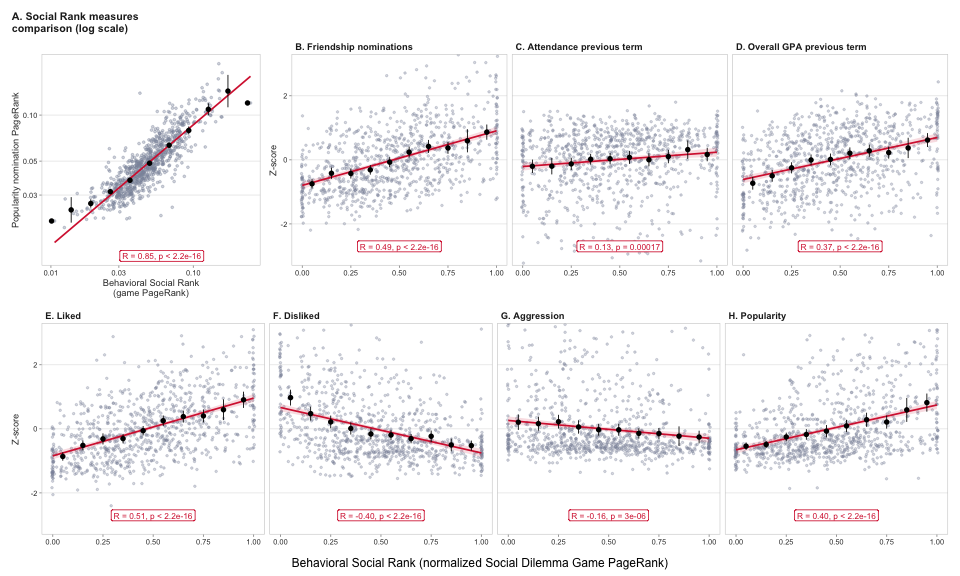

In [ ]:
# Supporting Information layout (plotting code in figures/S9_figures.R)
figure_s30 <- plot_figure_s30(students, bsr_correlates, s30_labels, s30_titles)
figure_s30

In [ ]:
iwalk(table_s53, ~ save_table(.x, paste0("S9_table_s53_observed_", str_replace_all(tolower(.y), "[^a-z]+", "_"))))
iwalk(table_s54, ~ save_table(.x, paste0("S9_table_s54_filtered_", str_replace_all(tolower(.y), "[^a-z]+", "_"))))
iwalk(table_s55, ~ save_table(.x, paste0("S9_table_s55_asymmetric_", str_replace_all(tolower(.y), "[^a-z]+", "_"))))
write_csv(students %>% select(student_id, class_id, bsr_pagerank, bsr), here("data", "generated", "behavioral_rank.csv"))
save_si_figure(figure_s29, "S9_figure_s29_bsr_cooperation", 9, 5.5)
save_si_figure(figure_s30, "S9_figure_s30_bsr_correlates", 10, 6)